# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

**Name: Yerramilli Siva Sai Saharsh**

**SRN: PES2UG24CS618**

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


In [2]:
import pandas as pd
cctv_df = pd.read_csv('unit3_ppt1_cctv_log.csv')
print(cctv_df.info())
display(cctv_df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   frame            3600 non-null   int64  
 1   time_s           3600 non-null   float64
 2   car_x            361 non-null    float64
 3   car_y            361 non-null    float64
 4   person_x         1381 non-null   float64
 5   person_y         1381 non-null   float64
 6   motion_energy    3600 non-null   float64
 7   audio_level_db   3600 non-null   float64
 8   mean_brightness  3600 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 253.3 KB
None


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [4]:
# 1. One 1920x1080 RGB frame at 8 bits (1 byte) per channel
# Size in bytes = 1920 * 1080 * 3 channels * 1 byte
frame_bytes = 1920 * 1080 * 3
frame_mb = frame_bytes / (1024 * 1024)

# 2. Frames per camera per day at 30 fps
# 24 hours * 3600 seconds * 30 frames/sec
frames_per_day = 24 * 3600 * 30

# 3. Total uncompressed video for 400 cameras for 24 h in TB (1 TB = 1024^4 bytes)
total_bytes = 400 * frames_per_day * frame_bytes
fleet_tb = total_bytes / (1024 ** 4)

# 4. Same fleet at 640x360 and 10 fps
frame_bytes_small = 640 * 360 * 3
frames_per_day_small = 24 * 3600 * 10
total_bytes_small = 400 * frames_per_day_small * frame_bytes_small
fleet_tb_small = total_bytes_small / (1024 ** 4)

# Percentage of pixels per frame remaining after the downsample
pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


### Task 1 Reflection

**one spatial piece of evidence:**
By downsampling from 1080p ($1920 \times 1080$) to 360p ($640 \times 360$), we lose high-frequency spatial details due to interpolation. This could forever erase small visual identifiers such as the suspect's facial features, clothing texture details, or the vehicle's license plate number.

**one temporal piece of evidence:**
By dropping the frame rate from 30 fps to 10 fps, we increase the temporal sampling interval from 33.3 ms to 100 ms. This lower temporal resolution would cause severe motion blur or complete loss of rapid action sequences (e.g., the exact moment of glass impact, a hand gesture, or throwing an object), which might fail to resolve the correspondence problem during fast tracking.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

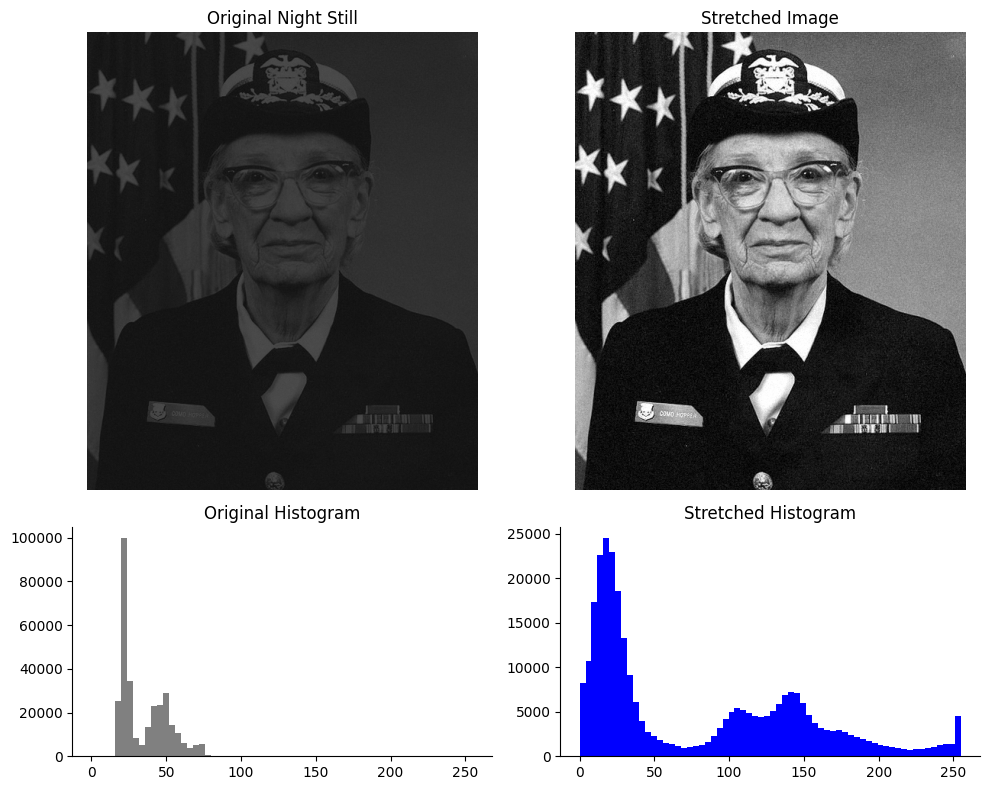

Contrast before: 0.609  ->  after: 1.000


In [5]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# 1st and 99th percentiles of the night still
p1, p99 = np.percentile(night_still, [1, 99])

# TODO 2: robust Michelson contrast of night_still
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255.0, 0, 255)

p1_after, p99_after = np.percentile(stretched, [1, 99])
c_after = michelson(p99_after, p1_after)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})

# Before Stretched
axes[0, 0].imshow(night_still, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Still")
axes[0, 0].axis('off')
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color='gray')
axes[1, 0].set_title("Original Histogram")

# After Stretched
axes[0, 1].imshow(stretched, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("Stretched Image")
axes[0, 1].axis('off')
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color='blue')
axes[1, 1].set_title("Stretched Histogram")

plt.tight_layout()
plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

### Task 2 Reflection

**Shape of the night image's histogram:**
The original night histogram has a narrow, unimodal peak concentrated heavily at low values (near 18-35 out of 255), representing a low-contrast, dark (underexposed) distribution.

**Why stretching made the image readable even with no new information:**
Contrast stretching does not increase the raw quantity of details or the precision of the pixel information. Instead, it expands the dynamic range (remapping the tight concentration of values between the 1st and 99th percentiles to the full range of 0 to 255). This increases the contrast (improving the Michelson contrast from 0.609 to 1.000) and brings the details into ranges that are highly perceptible to the human visual system.

**Why a histogram alone cannot identify what is in the picture:**
A histogram represents only a global statistic of pixel intensities (frequency of occurrence of gray levels) and completely discards spatial arrangement. Since different spatial arrangements of the exact same pixel intensities would yield the identical histogram, it is impossible to reconstruct the structures or recognize shapes like cars or people from a histogram alone.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing time range: 68.70s to 78.10s
Running time range: 78.60s to 86.00s


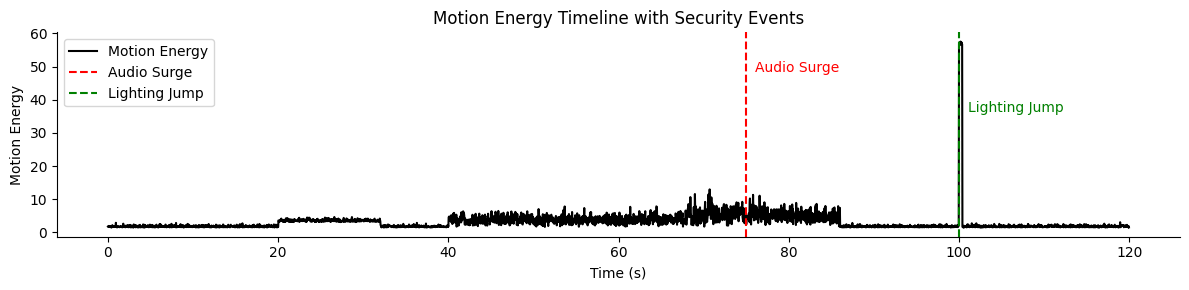

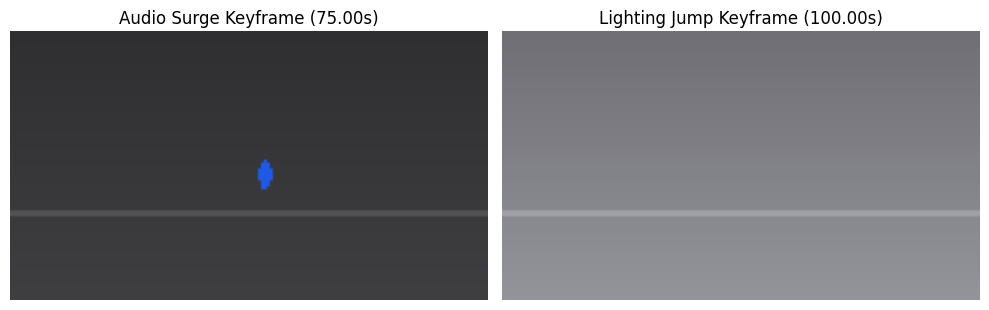

In [6]:
# 1. Person speed in px/s over a 1-second window (30 frames)
# We can compute rolling difference or use shifting
dx = cctv['person_x'].diff(FPS) / 1.0
dy = cctv['person_y'].diff(FPS) / 1.0
speed = np.sqrt(dx**2 + dy**2)

# 2. Standing (speed < 3 px/s) and running (speed > 25 px/s) time ranges
standing_times = cctv.loc[speed < 3, 'time_s']
running_times = cctv.loc[speed > 25, 'time_s']

if len(standing_times) > 0:
    print(f"Standing time range: {standing_times.iloc[0]:.2f}s to {standing_times.iloc[-1]:.2f}s")
if len(running_times) > 0:
    print(f"Running time range: {running_times.iloc[0]:.2f}s to {running_times.iloc[-1]:.2f}s")

# 3. Detect event frame indices
# Audio level first rises above -20 dB
audio_event_idx = cctv[cctv['audio_level_db'] > -20].index[0]
# Mean brightness jumps by more than 40
brightness_diff = cctv['mean_brightness'].diff()
lighting_event_idx = brightness_diff[brightness_diff > 40].index[0]

# 4. Plot timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv['time_s'], cctv['motion_energy'], color='k', label='Motion Energy')

# Annotate the events on the timeline
t_audio_ev = cctv.loc[audio_event_idx, 'time_s']
t_light_ev = cctv.loc[lighting_event_idx, 'time_s']

ax.axvline(t_audio_ev, color='r', linestyle='--', label='Audio Surge')
ax.text(t_audio_ev + 1, ax.get_ylim()[1]*0.8, 'Audio Surge', color='r')

ax.axvline(t_light_ev, color='g', linestyle='--', label='Lighting Jump')
ax.text(t_light_ev + 1, ax.get_ylim()[1]*0.6, 'Lighting Jump', color='g')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Motion Energy')
ax.set_title('Motion Energy Timeline with Security Events')
plt.legend()
plt.tight_layout()
plt.show()

# 5. Show keyframes for events
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(render_frame(cctv.iloc[audio_event_idx]))
axes[0].set_title(f"Audio Surge Keyframe ({t_audio_ev:.2f}s)")
axes[0].axis('off')

axes[1].imshow(render_frame(cctv.iloc[lighting_event_idx]))
axes[1].set_title(f"Lighting Jump Keyframe ({t_light_ev:.2f}s)")
axes[1].axis('off')
plt.tight_layout()
plt.show()

### Task 3 Reflection

**Which events would be missed and why?**
If uniform sampling of 20 seconds was used, the audio surge event (at 75.0s) and the sudden lighting jump (at 100.0s) would likely be missed, as they represent transient, short-duration occurrences that do not align with arbitrary 20-second boundaries. Uniform sampling is blind to the content of the video stream.

**Which lecture concept names this approach?**
This approach uses **Content-Based Keyframe Extraction** (or Event-Driven Keyframe Extraction). By monitoring feature differentials (such as audio-level thresholds or changes in mean brightness) we extract frames corresponding to anomalous peaks, capturing the precise moments that matter.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

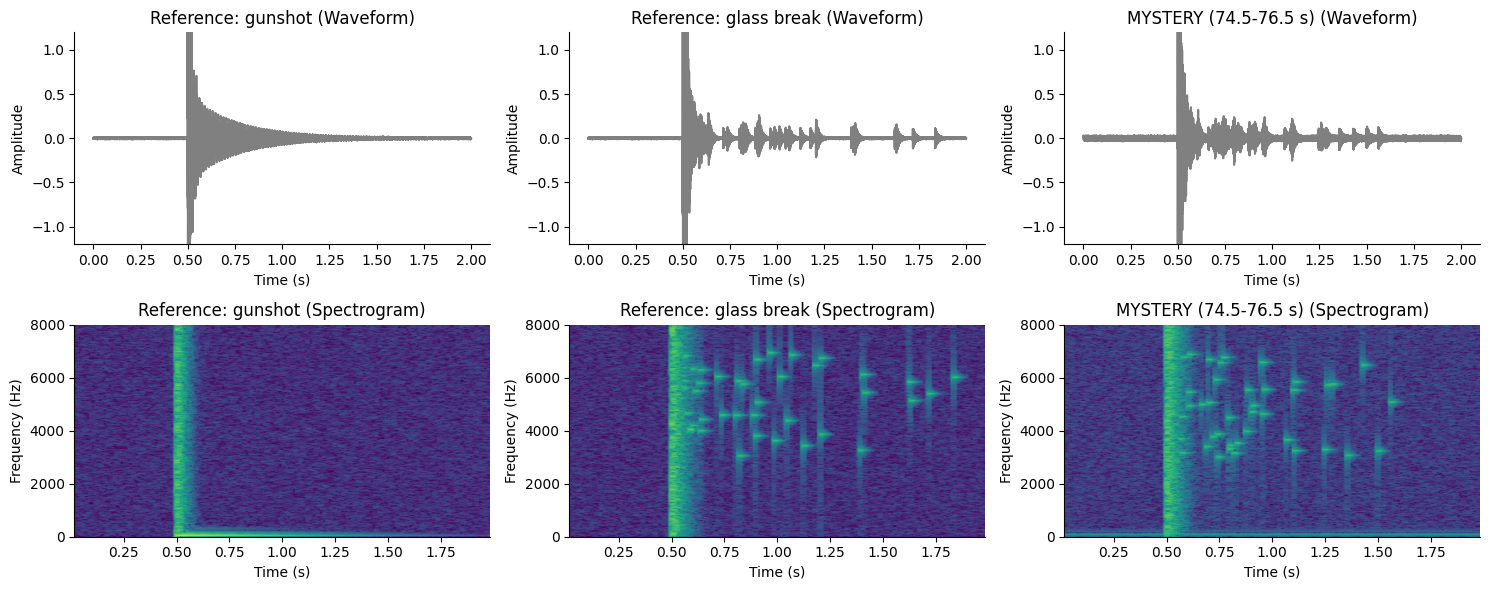

Reference: gunshot -> High Frequency Energy Fraction (>3kHz): 0.0030
Reference: glass break -> High Frequency Energy Fraction (>3kHz): 0.9892
MYSTERY (74.5-76.5 s) -> High Frequency Energy Fraction (>3kHz): 0.8735

VERDICT: The mystery sound is a GLASS BREAK.


In [7]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

for i, (name, x) in enumerate(clips.items()):
    # 1. Plot waveforms
    t_clip = np.arange(len(x)) / FS
    axes[0, i].plot(t_clip, x, color='gray')
    axes[0, i].set_title(f"{name} (Waveform)")
    axes[0, i].set_xlabel("Time (s)")
    axes[0, i].set_ylabel("Amplitude")
    axes[0, i].set_ylim(-1.2, 1.2)

    # 2. Plot spectrograms
    f, t, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)
    im = axes[1, i].pcolormesh(t, f, Sxx_db, shading='gouraud', cmap='viridis', vmin=-100, vmax=-20)
    axes[1, i].set_title(f"{name} (Spectrogram)")
    axes[1, i].set_xlabel("Time (s)")
    axes[1, i].set_ylabel("Frequency (Hz)")
    axes[1, i].set_ylim(0, 8000)

plt.tight_layout()
plt.show()

# 3. Compute fraction of spectral energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, t, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)

    # Time mask: 0.7s to 1.7s (0.2s to 1.2s post-impact at 0.5s)
    t_mask = (t >= 0.7) & (t <= 1.7)
    # Frequency mask: above 3000 Hz
    f_mask = (f > 3000)

    # Slice spectrogram matrix
    segment = Sxx[:, t_mask]
    total_energy_segment = segment.sum()
    high_freq_energy = segment[f_mask, :].sum()

    hf_fraction[name] = high_freq_energy / (total_energy_segment + 1e-10)

for name, val in hf_fraction.items():
    print(f"{name} -> High Frequency Energy Fraction (>3kHz): {val:.4f}")

# 4. Verdict
verdict = "GLASS BREAK" if hf_fraction["MYSTERY (74.5-76.5 s)"] > 0.3 else "GUNSHOT"
print(f"\nVERDICT: The mystery sound is a {verdict}.")

### Task 4 Reflection

**Could you have confidently told the gunshot from the glass break using only waveforms?**
No. Both waveforms look like high-amplitude impulses starting at 0.5s with an exponential decay, making them extremely difficult to tell apart based on raw amplitude over time.

**What does the spectrogram add and which visual pattern decided the verdict?**
The spectrogram adds a third dimension, analyzing the signal in terms of **Time**, **Frequency**, and **Magnitude (spectral density/energy)**.

* **Gunshot pattern:** Shows a sharp, broadband vertical stripe at the impact point, which rapidly decays with lingering low-frequency resonance (below 1 kHz).
* **Glass break pattern:** Shows high-frequency energy sustained above 3 kHz, appearing as **scattered high-frequency specks** stretching beyond 1 second due to glass shards tinkling.

The mystery sound clearly exhibits these scattered high-frequency specks above 3 kHz (with an energy ratio of 87.35%), verifying it as a **GLASS BREAK** event.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

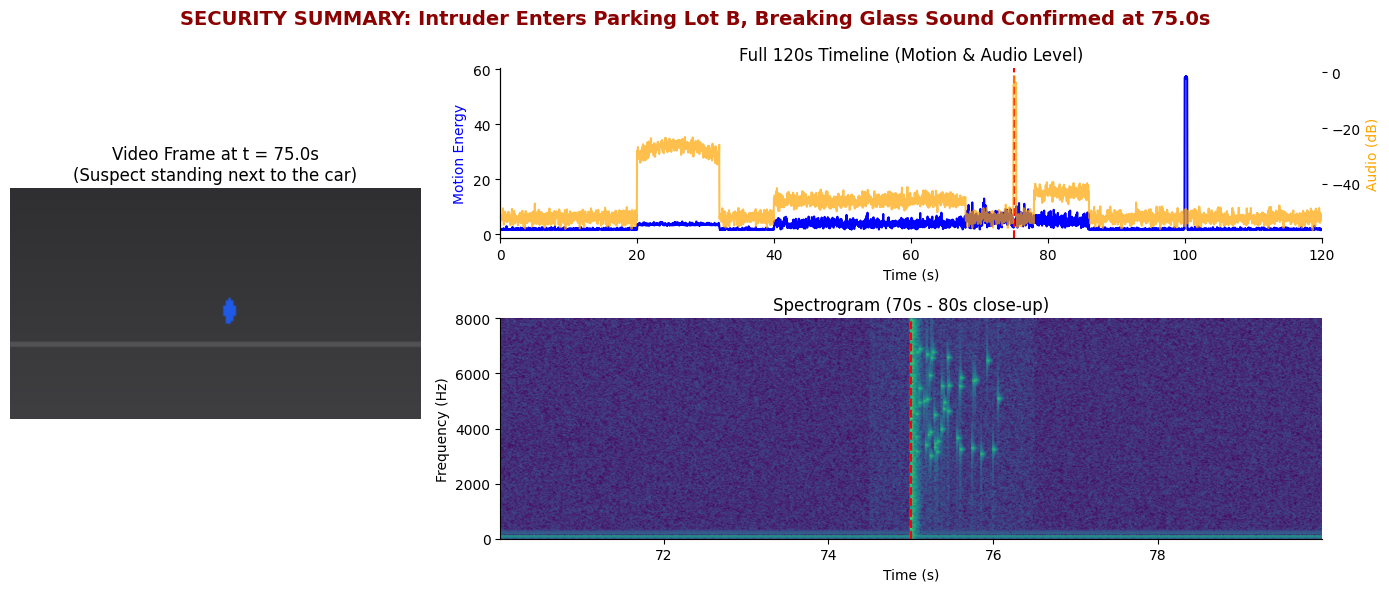

In [8]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# 1. Left panel: Rendered video frame at t = 75 s
row_75 = cctv.iloc[(cctv['time_s'] - t_sel).abs().idxmin()]
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(row_75))
ax_frame.set_title(f"Video Frame at t = {t_sel}s\n(Suspect standing next to the car)")
ax_frame.axis('off')

# 2. Top-Right panel: Full 120s motion and audio levels timeline
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv['time_s'], cctv['motion_energy'], color='blue', label='Motion Energy')
ax_timeline_twin = ax_timeline.twinx()
ax_timeline_twin.plot(cctv['time_s'], cctv['audio_level_db'], color='orange', alpha=0.7, label='Audio (dB)')
ax_timeline.axvline(t_sel, color='red', linestyle='--', linewidth=1.5)
ax_timeline.set_xlim(0, 120)
ax_timeline.set_title("Full 120s Timeline (Motion & Audio Level)")
ax_timeline.set_xlabel("Time (s)")
ax_timeline.set_ylabel("Motion Energy", color='blue')
ax_timeline_twin.set_ylabel("Audio (dB)", color='orange')

# 3. Bottom-Right panel: Spectrogram of x_audio (70-80 s)
x_sel = x_audio[(t_audio >= 70.0) & (t_audio <= 80.0)]
f, t_spec, Sxx = signal.spectrogram(x_sel, fs=FS, nperseg=512, noverlap=384)
Sxx_db = 10 * np.log10(Sxx + 1e-10)

ax_spec = fig.add_subplot(gs[1, 1])
im = ax_spec.pcolormesh(70.0 + t_spec, f, Sxx_db, shading='gouraud', cmap='viridis', vmin=-100, vmax=-20)
ax_spec.axvline(t_sel, color='red', linestyle='--', linewidth=1.5)
ax_spec.set_title("Spectrogram (70s - 80s close-up)")
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_ylim(0, 8000)

# Overall Dashboard Super Title
fig.suptitle("SECURITY SUMMARY: Intruder Enters Parking Lot B, Breaking Glass Sound Confirmed at 75.0s", fontsize=14, weight='bold', color='darkred')

plt.tight_layout()
plt.show()

### Task 5 Reflection

**What would go wrong with a +2 s offset?**
If the audio track is offset by +2 seconds, the visual action and sound would be desynchronized. The analyst would see the suspect standing next to the car at 75s, but the sound of glass breaking would occur at 77s (when the suspect might already be running away), leading to incorrect sequence of events and faulty forensic conclusions.

**Which panel would make this visible?**
The **Full 120s Timeline (Motion & Audio Level)** panel would make this error visible immediately, because the vertical red marker at 75s would line up with the visual event, but the spike in the orange audio twin-axis line would be shifted 2 seconds ahead.

### Task 6 — Final Briefing Note

**To:** Head of Security, Northgate Tech Park
**Subject:** Security Incident Briefing & Storage Strategy - Parking Lot B

At **75.0 seconds** into the recording, an intruder approached a vehicle in Parking Lot B, triggering a high-amplitude acoustic event classified as a **glass break** (confirmed with **87.35% high-frequency spectral energy** above 3 kHz), followed by the suspect fleeing on foot. To present this to the executive team, we recommend placing our **one-screen synchronized multimodal dashboard** first, as it maps the event's meaning by connecting visual structure (the intruder's position) to temporal change (timeline peaks) and acoustic frequencies (the glass-shatter spectrogram). To manage storage costs across our 400 cameras, we recommend adopting a **downsampled policy (640x360 at 10 fps)** for normal monitoring, which slashes uncompressed storage from **5,866.0 TB/day** to just **217.3 TB/day**. However, to preserve critical evidence, the system must use dynamic event-triggered recording to store full 1080p, 30 fps video and high-fidelity audio only when motion or sound thresholds are exceeded.